In [3]:
!pip install -q ultralytics

import os
from pathlib import Path

import pandas as pd
import ultralytics
from IPython.display import Image as IPyImage, display
from ultralytics import YOLO

ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


# dataset
The dataset is manually created with three classes: `facemask`,`glasses`, and `hats`.

In [6]:
import zipfile
from pathlib import Path

zip_path = Path('/content/dataset.zip')
if not zip_path.exists():
    zip_path = Path('dataset.zip')

extract_to = Path('/content/datasets')
extract_to.mkdir(parents=True, exist_ok=True)

if zip_path.exists():
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"Extracted {zip_path} to {extract_to} successfully!")
else:
    print("Error: dataset.zip file not found. Please upload it to Colab.")

Extracted /content/dataset.zip to /content/datasets successfully!


# config

In [1]:
DATA_YAML = '/content/datasets/data.yaml'
RUNS_DIR = '/content/runs'
IMG_SIZE = 640
BATCH = 16
WORKERS = 2
EPOCHS = 30
SEED = 67

PER_STAGE = EPOCHS // 3
BASELINE = dict(name='full_finetune', epochs=EPOCHS, freeze=None, lr0=0.001, warmup=3, close_mosaic=10)
STAGES = [
    dict(name='backbone_frozen', epochs=PER_STAGE, freeze=11, lr0=0.001, warmup=3, close_mosaic=0),
    dict(name='partial_unfreeze', epochs=PER_STAGE, freeze=5, lr0=0.0005, warmup=1, close_mosaic=0),
    dict(name='full_unfreeze', epochs=PER_STAGE, freeze=None, lr0=0.0002, warmup=1, close_mosaic=5),
]

In [4]:
def weights(name):
    return Path(RUNS_DIR) / name / 'weights' / 'best.pt'

def train_cmd(s, start):
    assert Path(DATA_YAML).exists(), f'{DATA_YAML} not found'
    parts = [
        'yolo detect train', f'model={start}', f'data={DATA_YAML}',
        f'imgsz={IMG_SIZE}', f'batch={BATCH}', f'workers={WORKERS}', f'seed={SEED}',
        'optimizer=AdamW', f"epochs={s['epochs']}", f"lr0={s['lr0']}",
        f"warmup_epochs={s['warmup']}", f"close_mosaic={s['close_mosaic']}",
        f'project={RUNS_DIR}', f"name={s['name']}", 'exist_ok=True',
    ]
    if s['freeze'] is not None:
        parts.append(f"freeze={s['freeze']}")
    return ' '.join(parts)

layers = list(YOLO('yolo11n.pt').model.model)

def trainable(freeze):
    return sum(p.numel() for l in layers[(freeze or 0):] for p in l.parameters())

display(pd.DataFrame([{
    'run': s['name'], 'epochs': s['epochs'],
    'frozen layers': 'none' if s['freeze'] is None else f"0-{s['freeze'] - 1}",
    'trainable params': f"{trainable(s['freeze']):,}",
    'lr0': s['lr0'], 'close_mosaic': s['close_mosaic'],
} for s in [BASELINE] + STAGES]))

,run,epochs,frozen layers,trainable params,lr0,close_mosaic
0,full_finetune,30,none,"2,624,080",0.0010,10
1,backbone_frozen,10,0-10,"1,258,608",0.0010,0
2,partial_unfreeze,10,0-4,"2,549,232",0.0005,0
3,full_unfreeze,10,none,"2,624,080",0.0002,5


# Training

full fine-tuning: all trainable layers

In [ ]:
cmd = train_cmd(BASELINE, 'yolo11n.pt')
print(cmd)
!{cmd}

yolo detect train model=yolo11n.pt data=/content/datasets/data.yaml imgsz=640 batch=16 workers=2 seed=67 optimizer=AdamW epochs=30 lr0=0.001 warmup_epochs=3 close_mosaic=10 project=/content/runs name=full_finetune exist_ok=True
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None,

neck + head layers trainable

In [ ]:
cmd = train_cmd(STAGES[0], 'yolo11n.pt')
print(cmd)
!{cmd}

yolo detect train model=yolo11n.pt data=/content/datasets/data.yaml imgsz=640 batch=16 workers=2 seed=67 optimizer=AdamW epochs=10 lr0=0.001 warmup_epochs=3 close_mosaic=0 project=/content/runs name=backbone_frozen exist_ok=True freeze=11
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, i

unfreeze first 5 layers from previous the previous stage

In [7]:
start = weights(STAGES[0]['name'])
assert start.exists(), 'Run stage 1 first'
cmd = train_cmd(STAGES[1], start)
print(cmd)
!{cmd}

yolo detect train model=/content/runs/backbone_frozen/weights/best.pt data=/content/datasets/data.yaml imgsz=640 batch=16 workers=2 seed=67 optimizer=AdamW epochs=10 lr0=0.0005 warmup_epochs=1 close_mosaic=0 project=/content/runs name=partial_unfreeze exist_ok=True freeze=5
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=5, hsv_h=0.015,

all layers unfrozen

In [8]:
start = weights(STAGES[1]['name'])
assert start.exists(), 'Run stage 2 first'
cmd = train_cmd(STAGES[2], start)
print(cmd)
!{cmd}

yolo detect train model=/content/runs/partial_unfreeze/weights/best.pt data=/content/datasets/data.yaml imgsz=640 batch=16 workers=2 seed=67 optimizer=AdamW epochs=10 lr0=0.0002 warmup_epochs=1 close_mosaic=5 project=/content/runs name=full_unfreeze exist_ok=True
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0

# Evaluation

In [10]:
RUNS = {'full fine-tuning': BASELINE['name']}
for i, s in enumerate(STAGES):
    what = 'all layers trainable' if s['freeze'] is None else f"layers 0-{s['freeze'] - 1} frozen"
    RUNS[f'model {i + 1} {what}'] = s['name']

rows = []
for label, name in RUNS.items():
    w = weights(name)
    if not w.exists():
        print('missing:', label)
        continue
    m = YOLO(str(w))
    for split, tag in (('val', 'valid'), ('test', 'test')):
        r = m.val(data=DATA_YAML, split=split, imgsz=IMG_SIZE, batch=BATCH, workers=0,
                  plots=False, verbose=False)
        rows.append({'run': label, 'split': tag, 'P': r.box.mp, 'R': r.box.mr,
                     'mAP50': r.box.map50, 'mAP50-95': r.box.map})

display(pd.DataFrame(rows).set_index(['run', 'split']).round(3))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1725.8±722.6 MB/s, size: 33.8 KB)
val: Scanning /content/datasets/valid/labels.cache... 946 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 946/946 264.5Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 33, len(boxes) = 1100. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 5.7it/s 10.5s
                   all        946       1100      0.596      0.529      0.509      0.306
Speed: 0.6ms preprocess, 3.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2

P      R  mAP50  mAP50-95
run                          split                               
full fine-tuning             valid  0.596  0.529  0.509     0.306
                             test   0.623  0.537  0.530     0.317
model 1 layers 0-10 frozen   valid  0.576  0.512  0.478     0.282
                             test   0.531  0.490  0.462     0.259
model 2 layers 0-4 frozen    valid  0.603  0.509  0.499     0.300
                             test   0.588  0.509  0.495     0.294
model 3 all layers trainable valid  0.578  0.533  0.501     0.311
                             test   0.597  0.510  0.515     0.311

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1813.6±253.9 MB/s, size: 36.6 KB)
val: Scanning /content/datasets/test/labels.cache... 538 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 538/538 188.0Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 20, len(boxes) = 563. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 4.9it/s 7.0s
                   all        538        563      0.597       0.51      0.515      0.311
              facemask        414        417      0.271      0.128     0.0792     0.0127
                 'hats        124       

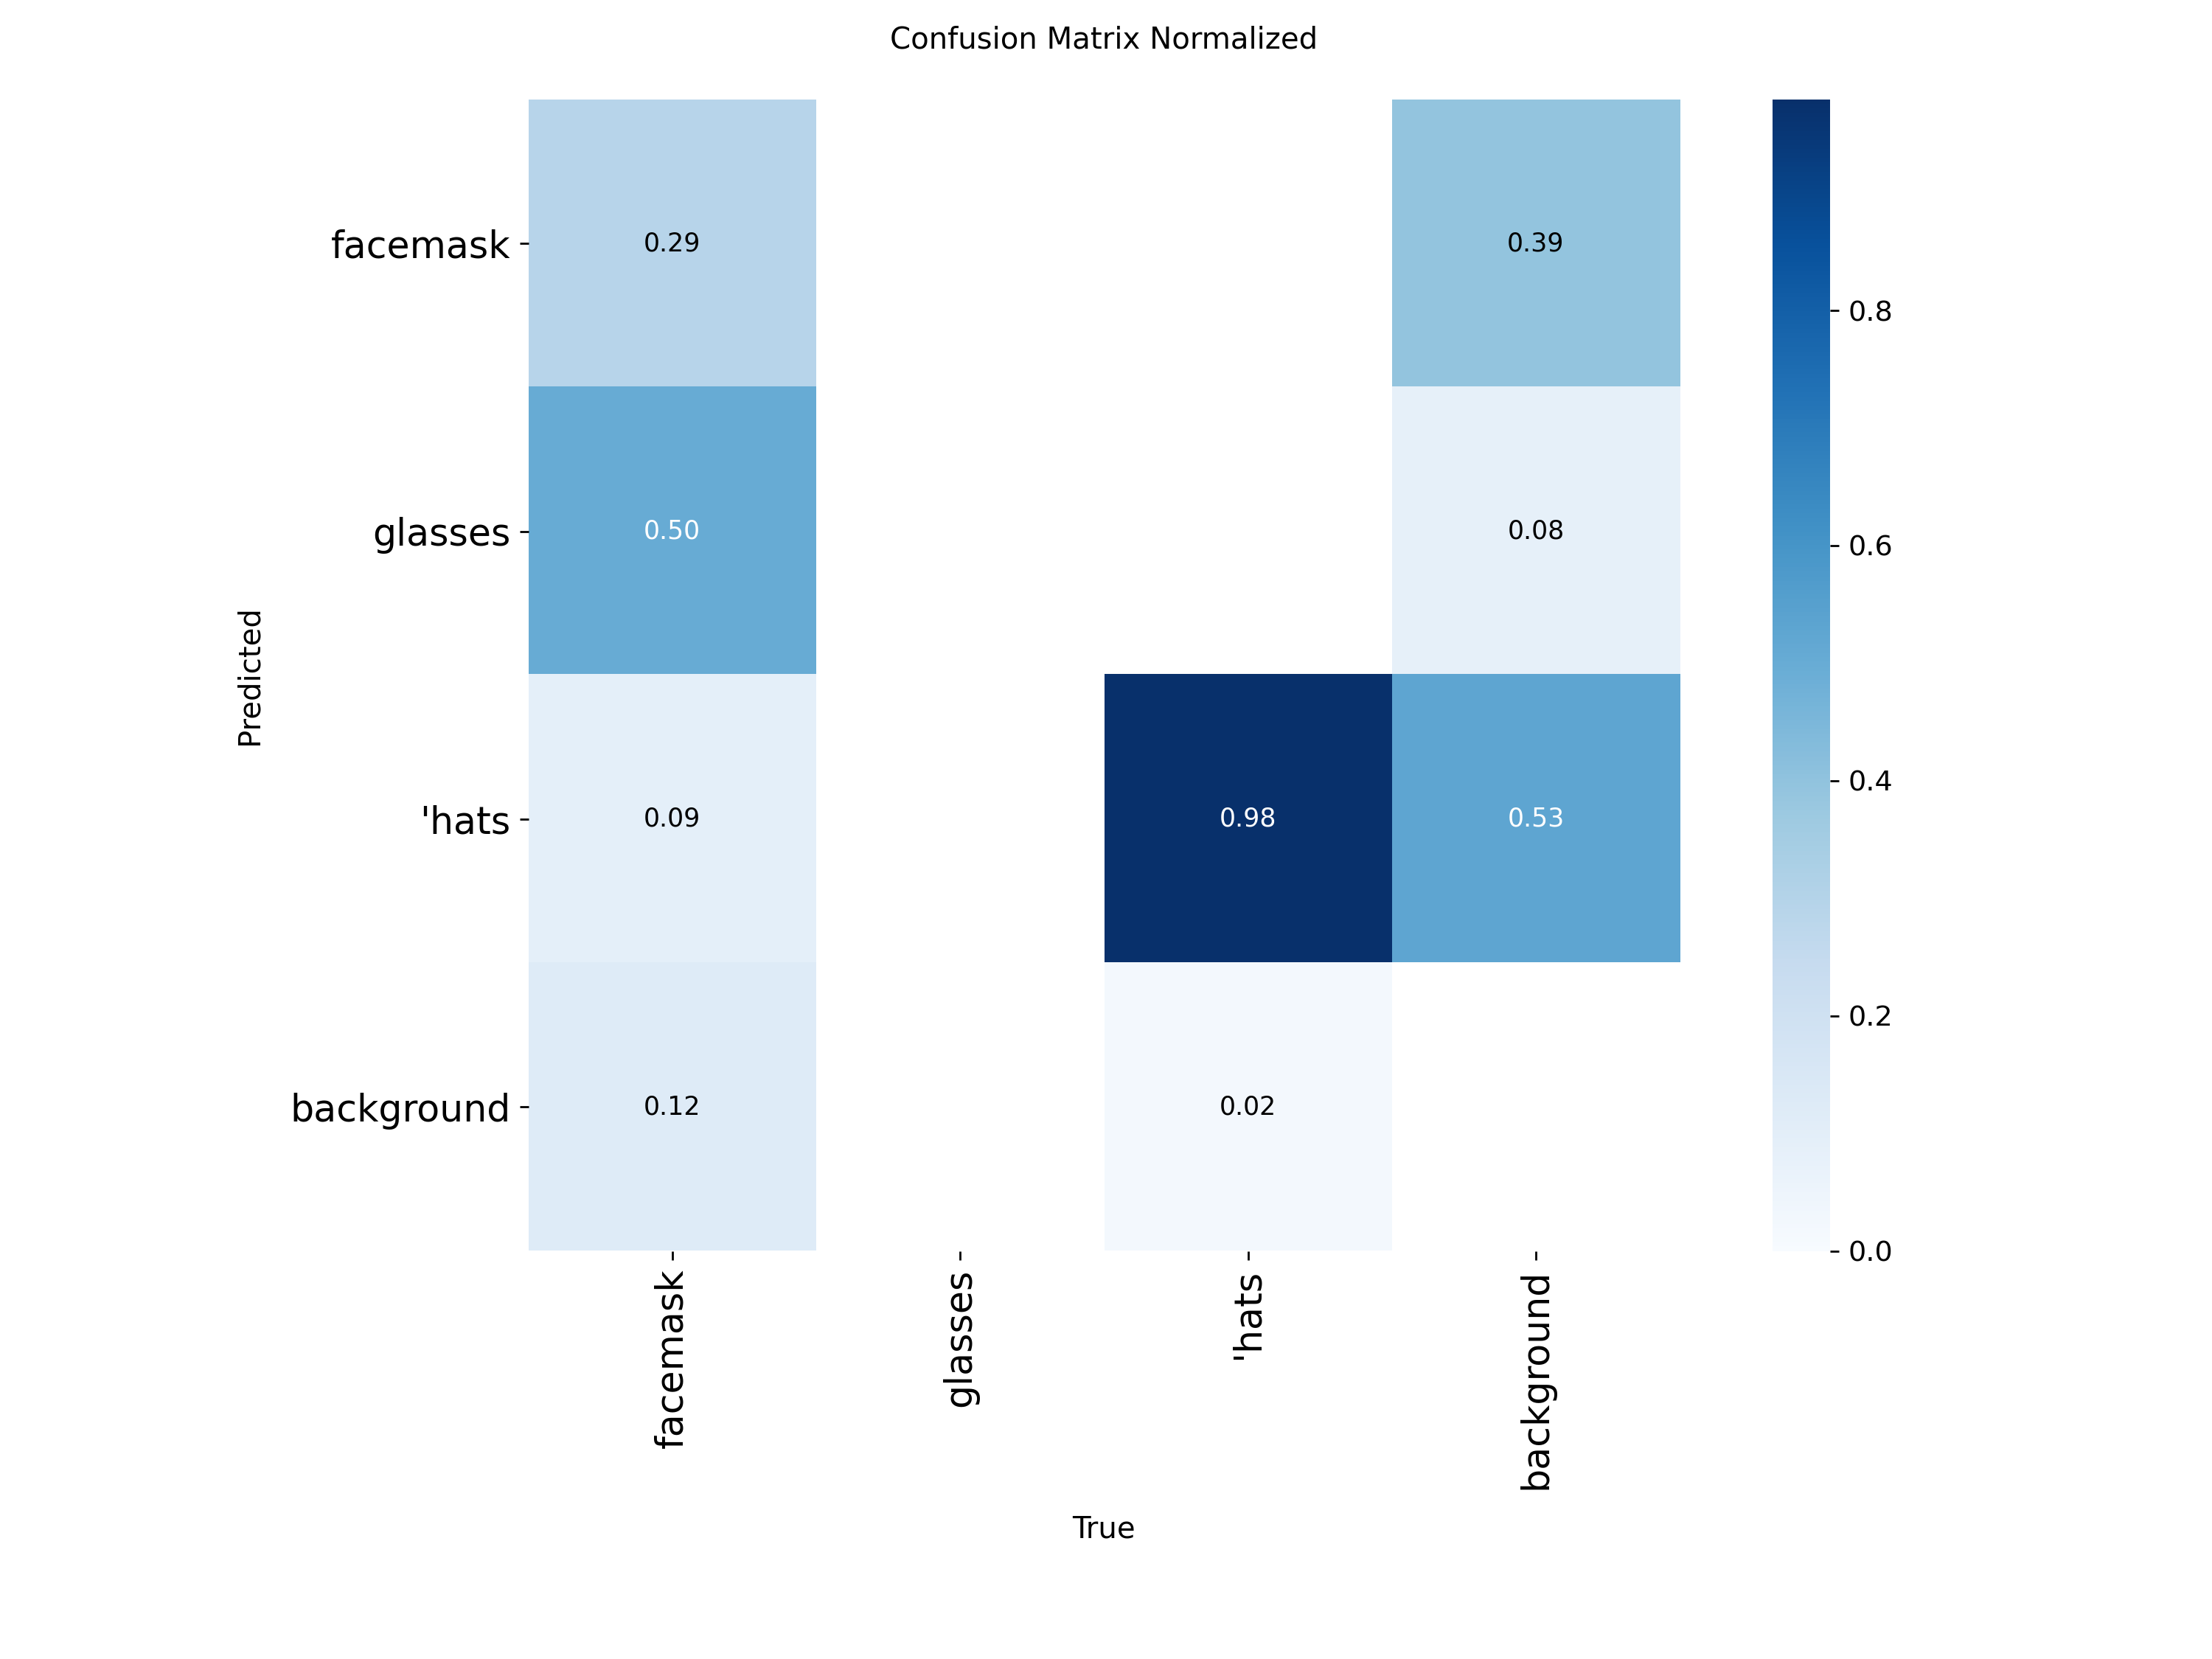

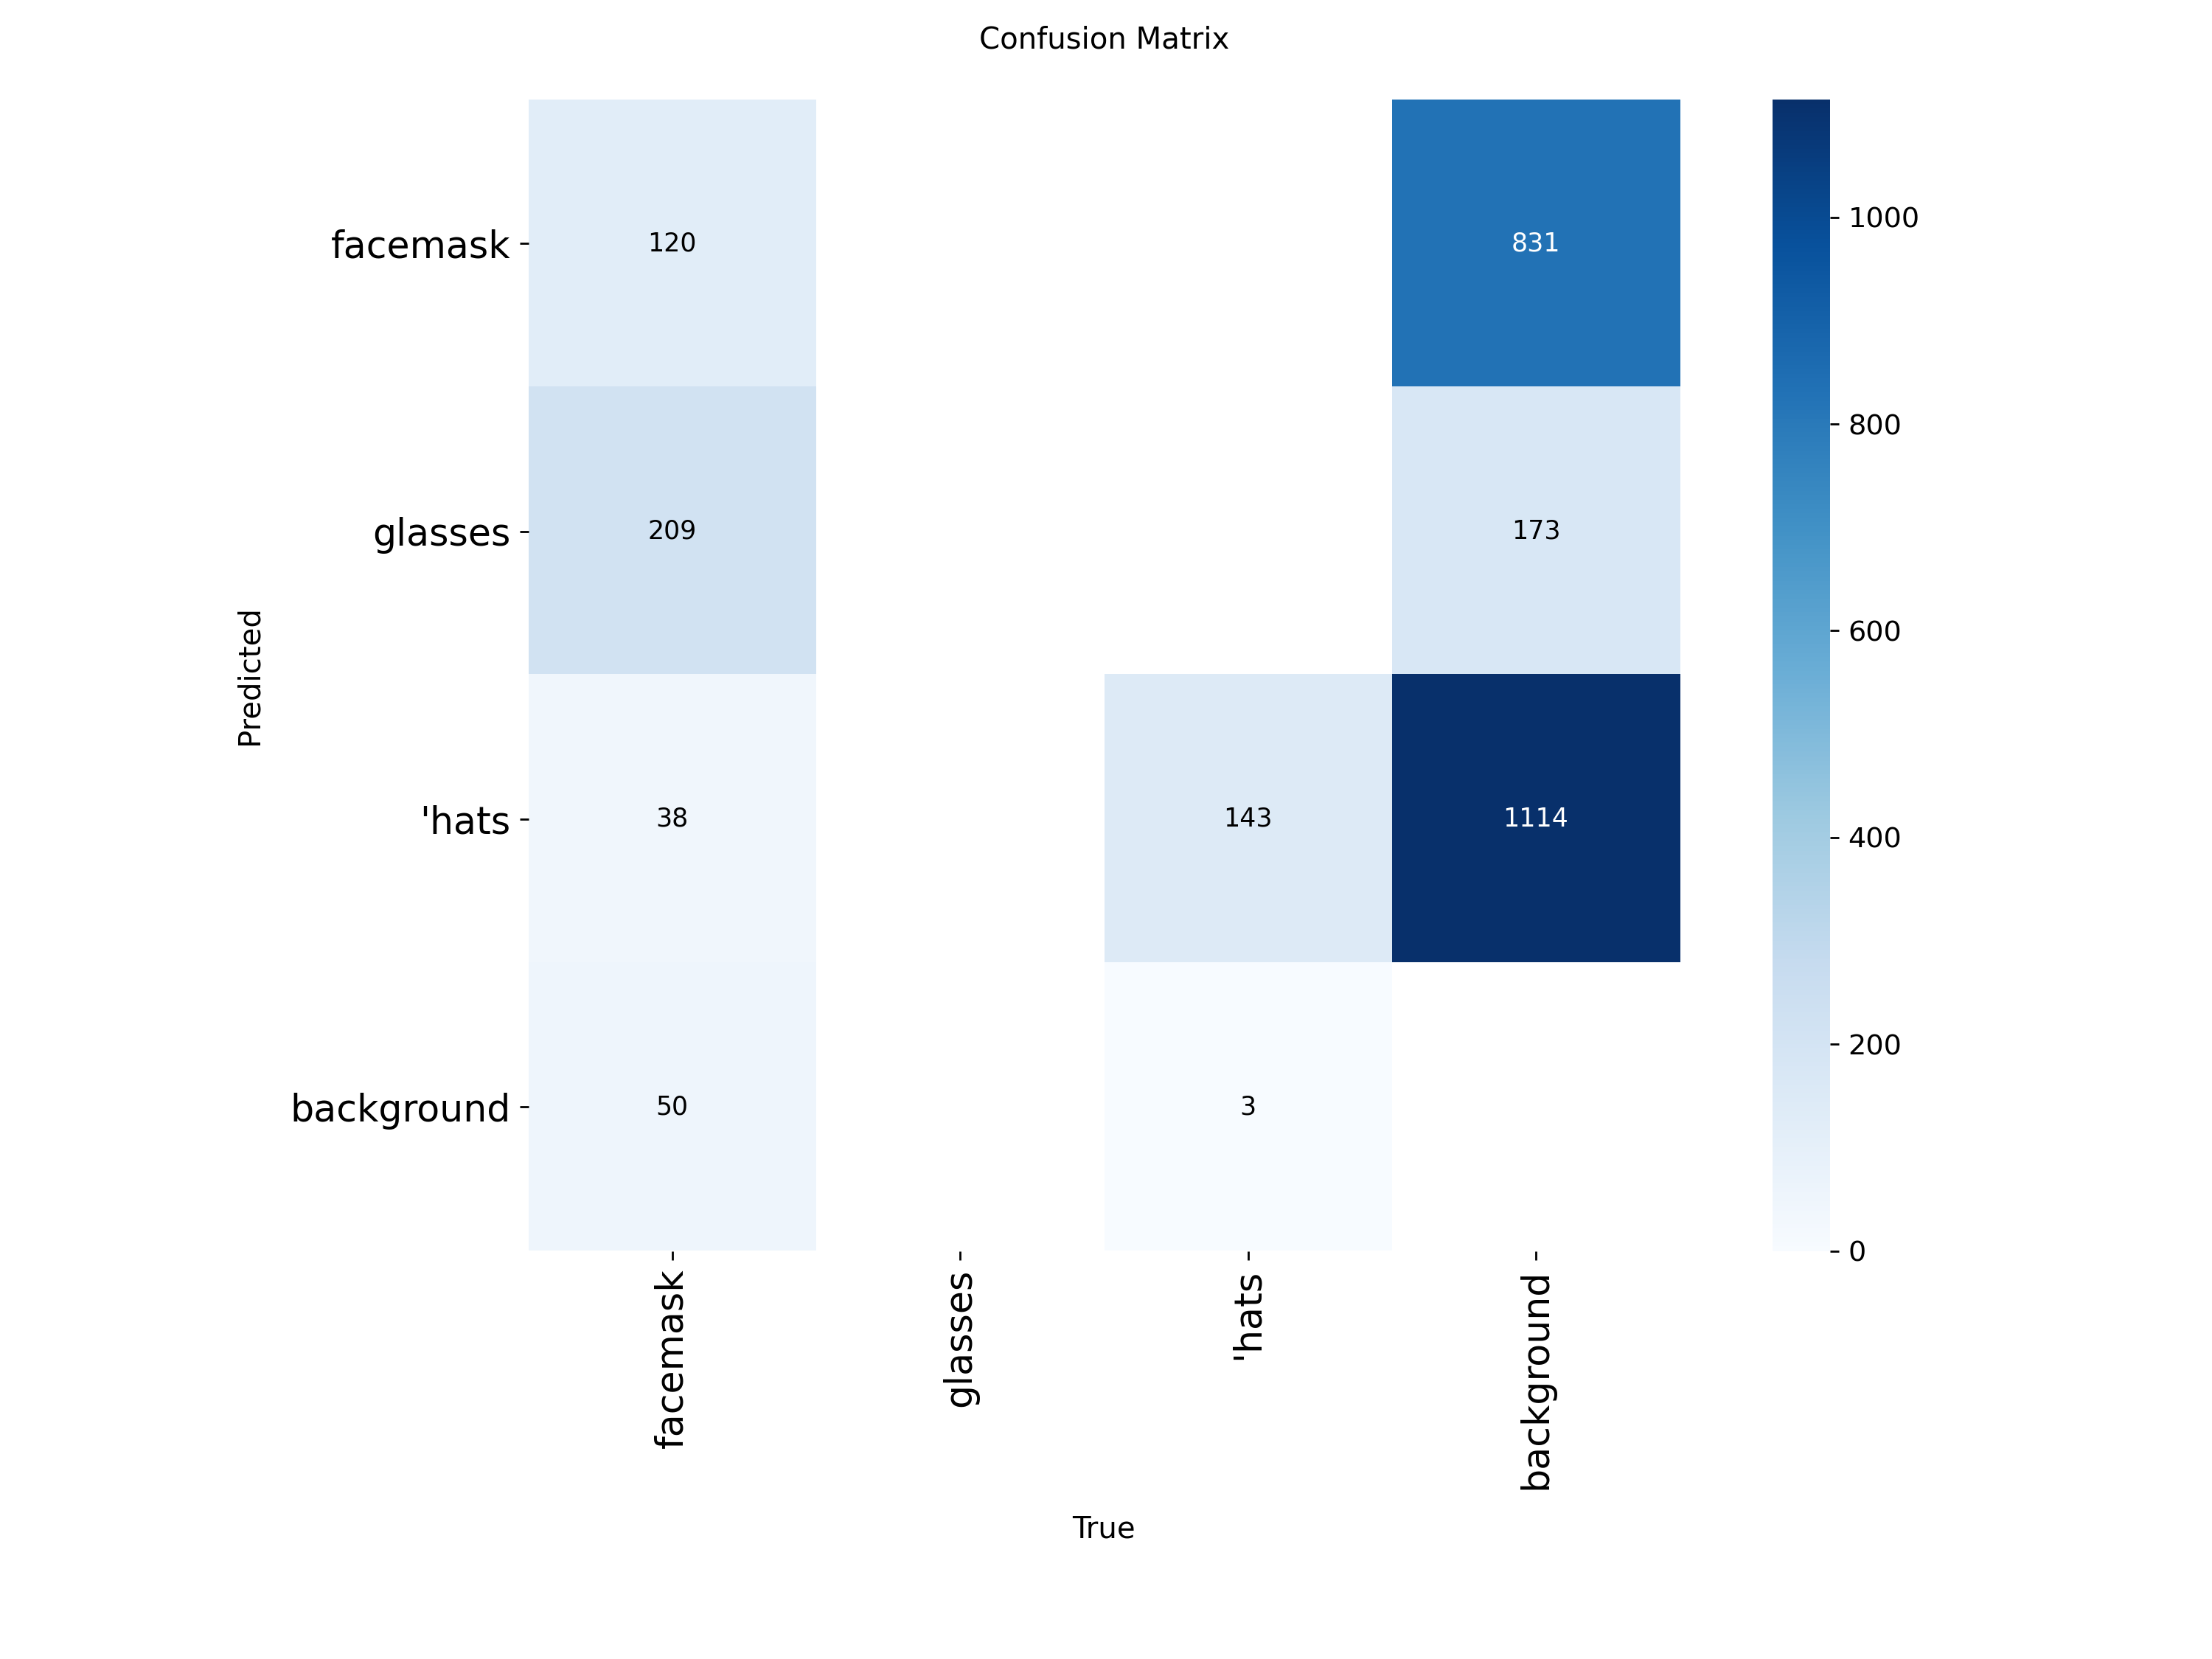

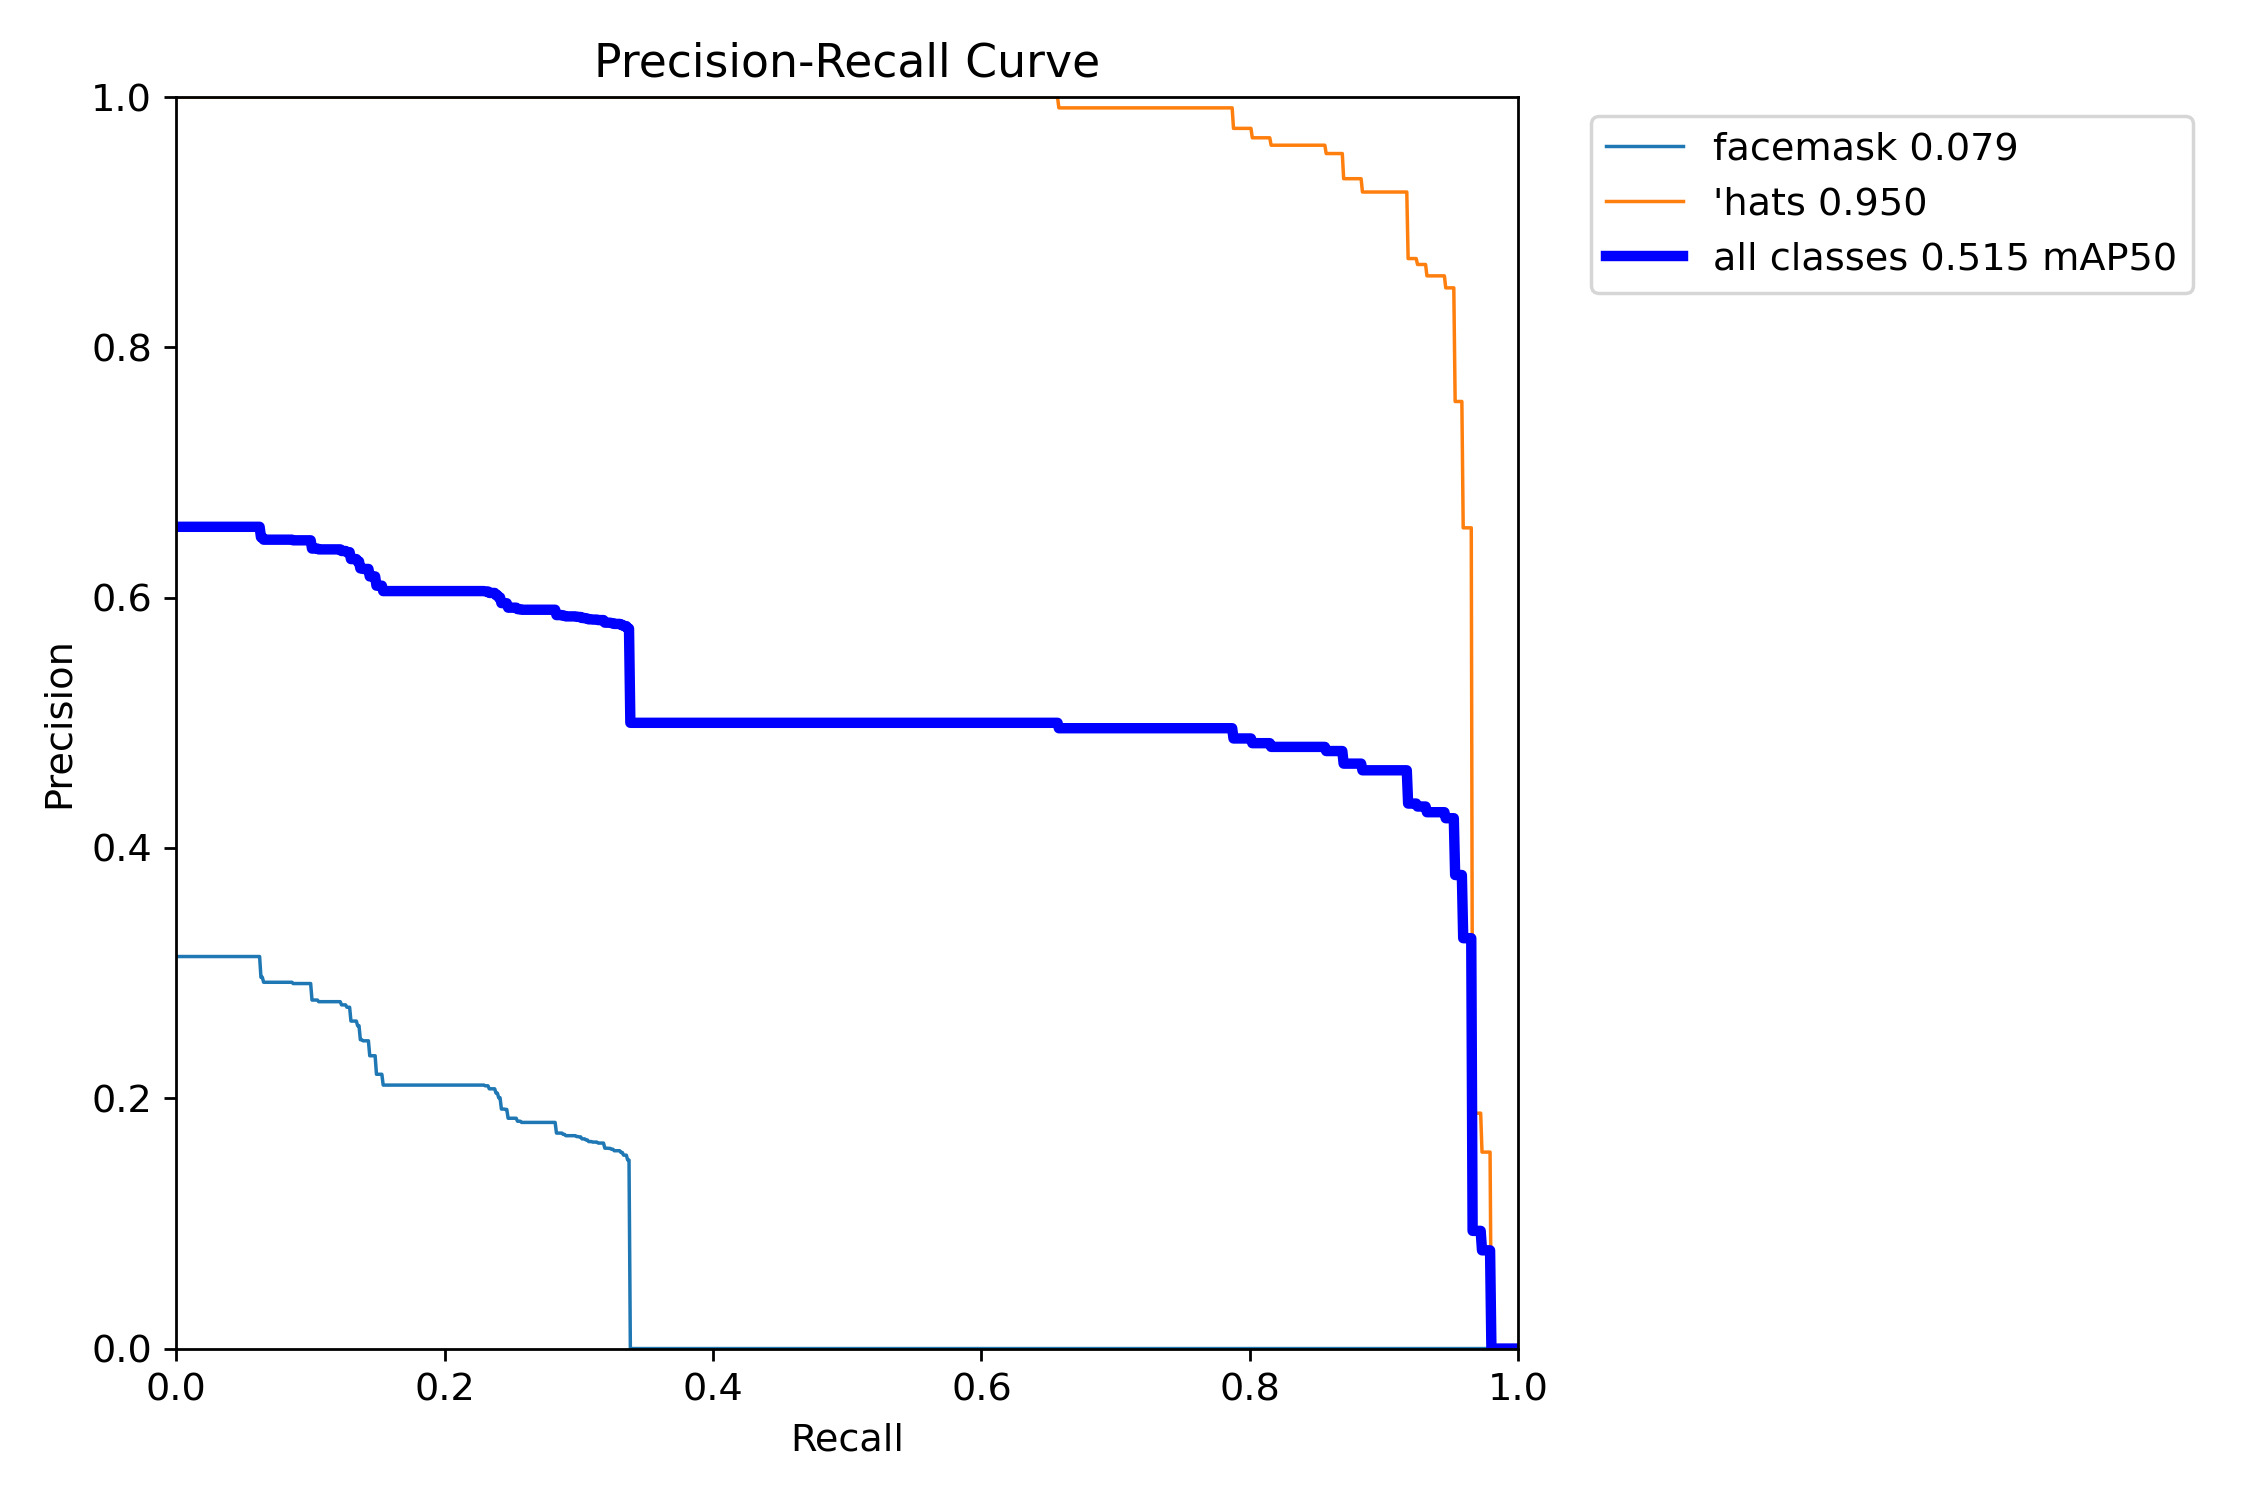

In [11]:
FINAL_WEIGHTS = weights(STAGES[-1]['name'])
final = YOLO(str(FINAL_WEIGHTS))
metrics = final.val(data=DATA_YAML, split='test', imgsz=IMG_SIZE, batch=BATCH, workers=0,
                    plots=True, project=RUNS_DIR, name='final_test_eval', exist_ok=True)

print(f"\nOverall    P={metrics.box.mp:.3f}  R={metrics.box.mr:.3f}  "
      f"mAP50={metrics.box.map50:.3f}  mAP50-95={metrics.box.map:.3f}")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"{metrics.names[c]:9s}  P={metrics.box.p[i]:.3f}  R={metrics.box.r[i]:.3f}  "
          f"mAP50={metrics.box.ap50[i]:.3f}  mAP50-95={metrics.box.ap[i]:.3f}")

EVAL_DIR = Path(metrics.save_dir)
for f in ('confusion_matrix_normalized.png', 'confusion_matrix.png', 'BoxPR_curve.png'):
    if (EVAL_DIR / f).exists():
        display(IPyImage(filename=str(EVAL_DIR / f)))

### demo

In [17]:
import base64, io

from google.colab import output
from IPython.display import JSON, Javascript, display
from PIL import Image

CONF = 0.4
live_model = YOLO(str(weights(STAGES[0]['name'])))


def detect(data_url):
    img = Image.open(io.BytesIO(base64.b64decode(data_url.split(',')[1]))).convert('RGB')
    r = live_model.predict(img, conf=CONF, imgsz=IMG_SIZE, verbose=False)[0]
    dets = [
        {'box': b, 'conf': round(c, 2), 'cls': int(k), 'label': r.names[int(k)]}
        for b, c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist())
    ]
    return JSON({'dets': dets})


output.register_callback('yolo.detect', detect)

display(Javascript('''
(async () => {
  const COLORS = ['#00c853', '#2979ff', '#ff6d00', '#d500f9', '#ffd600'];
  const stopBtn = document.createElement('button');
  stopBtn.textContent = 'Stop camera';
  const wrap = document.createElement('div');
  wrap.style.cssText = 'position:relative;width:640px;max-width:100%';
  const video = document.createElement('video');
  video.style.cssText = 'width:100%;display:block';
  video.autoplay = true; video.muted = true; video.playsInline = true;
  const overlay = document.createElement('canvas');
  overlay.style.cssText = 'position:absolute;left:0;top:0;width:100%;height:100%';
  wrap.append(video, overlay);
  document.body.append(stopBtn, wrap);

  let stream;
  try {
    stream = await navigator.mediaDevices.getUserMedia({video: true});
    video.srcObject = stream;
    await new Promise(res => video.onloadedmetadata = res);
    await video.play();
    google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

    const W = 640, H = Math.round(W * video.videoHeight / video.videoWidth);
    const cap = document.createElement('canvas');
    cap.width = W; cap.height = H; overlay.width = W; overlay.height = H;
    const cctx = cap.getContext('2d'), octx = overlay.getContext('2d');

    let running = true;
    stopBtn.onclick = () => { running = false; };

    while (running) {
      const t0 = performance.now();
      cctx.drawImage(video, 0, 0, W, H);
      const res = await google.colab.kernel.invokeFunction(
        'yolo.detect', [cap.toDataURL('image/jpeg', 0.6)], {});
      const dets = res.data['application/json'].dets;

      octx.clearRect(0, 0, W, H);
      octx.lineWidth = 3; octx.font = '16px sans-serif'; octx.textBaseline = 'top';
      for (const d of dets) {
        const [x1, y1, x2, y2] = d.box;
        const color = COLORS[d.cls % COLORS.length];
        const text = d.label + ' ' + d.conf.toFixed(2);
        const ty = Math.max(0, y1 - 22);
        octx.strokeStyle = color;
        octx.strokeRect(x1, y1, x2 - x1, y2 - y1);
        octx.fillStyle = color;
        octx.fillRect(x1, ty, octx.measureText(text).width + 8, 22);
        octx.fillStyle = '#fff';
        octx.fillText(text, x1 + 4, ty + 3);
      }
      octx.fillStyle = 'rgba(0,0,0,0.6)'; octx.fillRect(0, 0, 90, 24);
      octx.fillStyle = '#fff';
      octx.fillText((1000 / (performance.now() - t0)).toFixed(1) + ' FPS', 6, 4);
    }
  } catch (e) {
    wrap.insertAdjacentText('beforebegin', 'Error: ' + e);
  } finally {
    if (stream) stream.getTracks().forEach(t => t.stop());
    wrap.remove(); stopBtn.remove();
  }
})();
'''))

<IPython.core.display.Javascript object>